# Paper 15: LoRA: Low-Rank Adaptation of Large Language Models
**Authors**: Edward J. Hu, Yelong Shen, Phillip Wallis, Zeyuan Allen-Zhu, Yuanzhi Li, Shean Wang, Lu Wang, Weizhu Chen (Microsoft, 2021)

---

## 1. The Historical Breaking Point: The Fine-Tuning Storage & Serving Crisis
- **Massive Checkpoint Footprints**: Fine-tuning a 175B LLM requires storing a full 350 GB checkpoint per task.
- **Multi-Tenant Serving Throughput**: Serving multiple models requires swapping entire VRAM weights, destroying batching.
- **Adapter Latency Overhead**: Previous serial adapters (Houlsby et al.) added non-trivial inference latency due to sequential executions.

## 2. The Thought Experiment: The Intrinsic Dimensionality Hypothesis
Over-parametrized networks reside on a **low intrinsic dimension manifold** during task adaptation (Aghajanyan et al., 2020).
The required weight update $\Delta W$ has a low intrinsic rank $r \ll \min(d_{\text{in}}, d_{\text{out}})$.

$$\Delta W = B \cdot A$$
$$h = W_0 x + \frac{\alpha}{r} B A x$$

where $A \in \mathbb{R}^{r \times d_{\text{in}}}$ (Gaussian / Kaiming init) and $B \in \mathbb{R}^{d_{\text{out}} \times r}$ (**initialized to exact zeros**).

### Key Benefits:
1. **Zero Perturbation at Step 0**: $B = 0 \implies \Delta W = 0$, so initial predictions match the foundation model exactly.
2. **Zero Inference Latency**: During deployment, merge $W_{\text{merged}} = W_0 + \frac{\alpha}{r} BA$ into a single standard linear layer!
3. **Memory Savings**: Base parameters are frozen (`requires_grad = False`), drastically reducing optimizer state memory (e.g. Adam momentum buffers only allocated for $A$ and $B$).

In this notebook, you will test and verify:
- `LoRALinear`
- `merge()` and `unmerge()`
- `mark_only_lora_as_trainable`
- `apply_lora_to_model`

---
## Setup & Autoreload

In [2]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from model import (
    LoRALinear,
    mark_only_lora_as_trainable,
    apply_lora_to_model,
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch version: 2.14.1+cpu
CUDA available: False


---
## 1. Verify Step-Zero Exact Identity Invariant ($B = 0$)
Because $B = 0$ at initialization, LoRA contributes zero delta weight initially.

In [3]:
torch.manual_seed(42)
base_linear = nn.Linear(32, 64)
lora_linear = LoRALinear(base_layer=base_linear, r=4, lora_alpha=8.0)
lora_linear.eval()

x = torch.randn(2, 5, 32)
with torch.no_grad():
    out_base = base_linear(x)
    out_lora = lora_linear(x)

diff = (out_base - out_lora).abs().max().item()
print(f"Difference between base and LoRA output at Step 0: {diff:.2e}")
assert diff == 0.0
print("Step-Zero Identity Invariant PASSED!")

Difference between base and LoRA output at Step 0: 0.00e+00
Step-Zero Identity Invariant PASSED!


---
## 2. Test Weight Merge and Unmerge (Zero-Latency Inference)
During inference, merging the low-rank delta matrix into $W_0$ eliminates extra matrix multiplies.

In [4]:
layer = LoRALinear(in_features=32, out_features=48, r=8, lora_alpha=16.0)
layer.eval()
# Give non-zero weights to B to simulate trained adapter
nn.init.normal_(layer.lora_B.weight, std=0.05)

x = torch.randn(4, 32)
with torch.no_grad():
    out_unmerged = layer(x)

layer.merge()
assert layer.merged is True
with torch.no_grad():
    out_merged = layer(x)

diff = (out_unmerged - out_merged).abs().max().item()
print(f"Difference between unmerged and merged forward pass: {diff:.2e}")
assert diff < 1e-5

layer.unmerge()
assert layer.merged is False
print("Merge / Unmerge cycles PASSED!")

Difference between unmerged and merged forward pass: 4.77e-07
Merge / Unmerge cycles PASSED!


---
## 3. Verify Gradient Isolation via `mark_only_lora_as_trainable`
Verify that the base network is 100% frozen while only adapter parameters receive gradient updates.

In [5]:
model = nn.Sequential(
    LoRALinear(in_features=16, out_features=32, r=4),
    nn.ReLU(),
    LoRALinear(in_features=32, out_features=8, r=4),
)
mark_only_lora_as_trainable(model, bias="none")

trainable = [name for name, p in model.named_parameters() if p.requires_grad]
frozen = [name for name, p in model.named_parameters() if not p.requires_grad]

print("Trainable parameters:", trainable)
print("Frozen parameters:   ", frozen)
assert all("lora_" in name for name in trainable)
print("Gradient Isolation PASSED!")

Trainable parameters: ['0.lora_A.weight', '0.lora_B.weight', '2.lora_A.weight', '2.lora_B.weight']
Frozen parameters:    ['0.linear.weight', '0.linear.bias', '2.linear.weight', '2.linear.bias']
Gradient Isolation PASSED!


---
## 4. Single-Batch Adaptation with 100% Frozen Base Network
Adapt a completely frozen base model to a target synthetic dataset purely by training LoRA adapters.

Epoch 15 | Loss: 0.1043
Epoch 30 | Loss: 0.0231
Epoch 45 | Loss: 0.0045
Epoch 60 | Loss: 0.0010


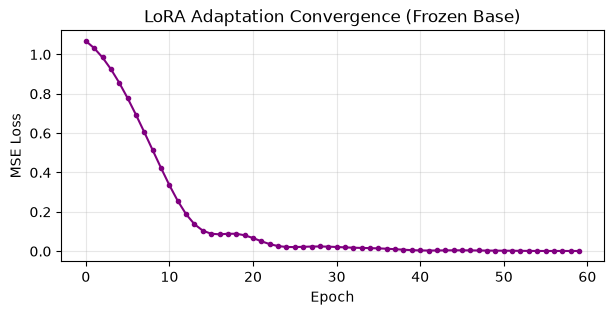

Adaptation overfit check PASSED! Final loss: 0.0010


In [6]:
torch.manual_seed(42)
B, in_dim, hidden_dim, out_dim = 4, 16, 32, 4
model = nn.Sequential(
    LoRALinear(in_features=in_dim, out_features=hidden_dim, r=4, lora_alpha=8.0),
    nn.GELU(),
    LoRALinear(in_features=hidden_dim, out_features=out_dim, r=4, lora_alpha=8.0),
)
mark_only_lora_as_trainable(model, bias="none")

optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-2)
criterion = nn.MSELoss()

x = torch.randn(B, in_dim)
target = torch.randn(B, out_dim)

losses = []
for epoch in range(60):
    optimizer.zero_grad()
    pred = model(x)
    loss = criterion(pred, target)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 15 == 0:
        print(f"Epoch {epoch+1:2d} | Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, marker='o', markersize=3, color='purple')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('LoRA Adaptation Convergence (Frozen Base)')
plt.grid(True, alpha=0.3)
plt.show()

assert losses[-1] < 0.05
print(f"Adaptation overfit check PASSED! Final loss: {losses[-1]:.4f}")